In [1]:
!pip install torch scikit-learn pandas matplotlib seaborn

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Set random seed
torch.manual_seed(42)

# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


# ================================================
# BREAST CANCER CLASSIFICATION USING PYTORCH
# ================================================

Epoch [10/100] Train Loss: 0.6617 Validation Loss: 0.6575
Epoch [20/100] Train Loss: 0.6292 Validation Loss: 0.6267
Epoch [30/100] Train Loss: 0.5873 Validation Loss: 0.5834
Epoch [40/100] Train Loss: 0.5351 Validation Loss: 0.5316
Epoch [50/100] Train Loss: 0.4867 Validation Loss: 0.4756
Epoch [60/100] Train Loss: 0.4206 Validation Loss: 0.4190
Epoch [70/100] Train Loss: 0.3729 Validation Loss: 0.3658
Epoch [80/100] Train Loss: 0.3236 Validation Loss: 0.3186
Epoch [90/100] Train Loss: 0.2789 Validation Loss: 0.2781
Epoch [100/100] Train Loss: 0.2590 Validation Loss: 0.2440

Accuracy: 0.9302325581395349

Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.88      0.90        32
      benign       0.93      0.96      0.95        54

    accuracy                           0.93        86
   macro avg       0.93      0.92      0.92        86
weighted avg       0.93      0.93      0.93        86



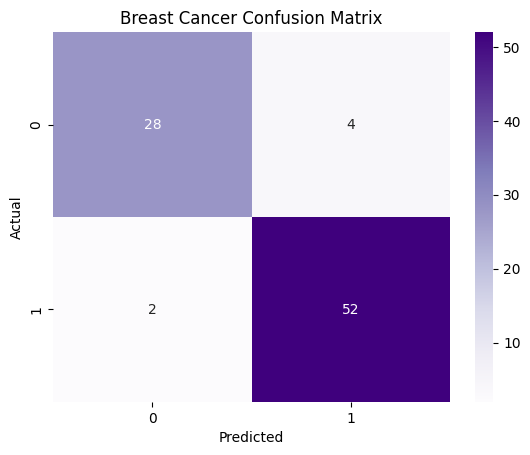

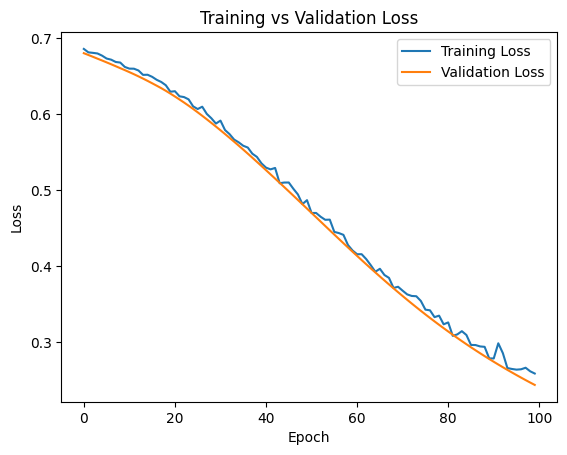

In [3]:




data = load_breast_cancer()

X = data.data
y = data.target


X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    random_state=42, stratify=y_temp
)


scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

#  Convert Data into PyTorch Tensors
X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
X_val = torch.tensor(X_val, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test, dtype=torch.float32).to(device)

y_train = torch.tensor(y_train, dtype=torch.float32).view(-1, 1).to(device)
y_val = torch.tensor(y_val, dtype=torch.float32).view(-1, 1).to(device)
y_test = torch.tensor(y_test, dtype=torch.float32).view(-1, 1).to(device)

#  Build MLP Model
class CancerMLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(30, 16),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(8, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)


model = CancerMLP().to(device)

#  Loss Function and Optimizer
criterion = nn.BCELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

#  Training
epochs = 100

train_losses = []
val_losses = []

for epoch in range(epochs):

    model.train()

    optimizer.zero_grad()

    predictions = model(X_train)

    loss = criterion(predictions, y_train)

    loss.backward()

    optimizer.step()

    train_losses.append(loss.item())

    # Validation
    model.eval()

    with torch.no_grad():
        val_predictions = model(X_val)
        val_loss = criterion(val_predictions, y_val)

    val_losses.append(val_loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {loss.item():.4f} "
            f"Validation Loss: {val_loss.item():.4f}"
        )

# Evaluation
model.eval()

with torch.no_grad():
    test_probabilities = model(X_test)
    test_predictions = (test_probabilities >= 0.5).int()

y_true = y_test.cpu().numpy()
y_pred = test_predictions.cpu().numpy()

print("\nAccuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    target_names=data.target_names
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Purples")
plt.title("Breast Cancer Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#  Loss Graph
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()



# =================================================
# IRIS CLASSIFICATION USING PYTORCH
# ================================================



Epoch [10/100] Train Loss: 1.1859 Validation Loss: 1.1787
Epoch [20/100] Train Loss: 1.1495 Validation Loss: 1.1480
Epoch [30/100] Train Loss: 1.1203 Validation Loss: 1.1195
Epoch [40/100] Train Loss: 1.0868 Validation Loss: 1.0904
Epoch [50/100] Train Loss: 1.0647 Validation Loss: 1.0583
Epoch [60/100] Train Loss: 1.0317 Validation Loss: 1.0229
Epoch [70/100] Train Loss: 0.9901 Validation Loss: 0.9822
Epoch [80/100] Train Loss: 0.9505 Validation Loss: 0.9374
Epoch [90/100] Train Loss: 0.9219 Validation Loss: 0.8903
Epoch [100/100] Train Loss: 0.8533 Validation Loss: 0.8422

Accuracy: 0.6521739130434783

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         7
  versicolor       0.50      0.12      0.20         8
   virginica       0.50      0.88      0.64         8

    accuracy                           0.65        23
   macro avg       0.67      0.67      0.61        23
weighted avg       0.65      0.65      

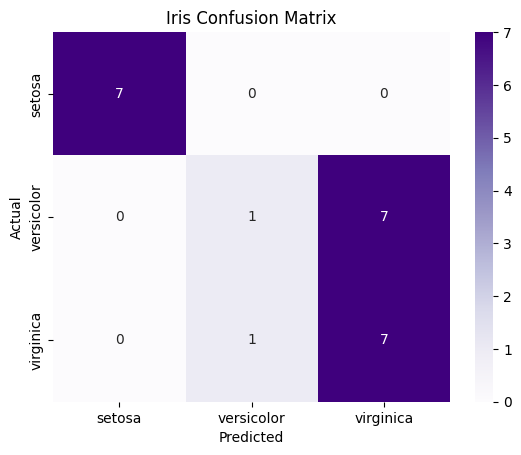

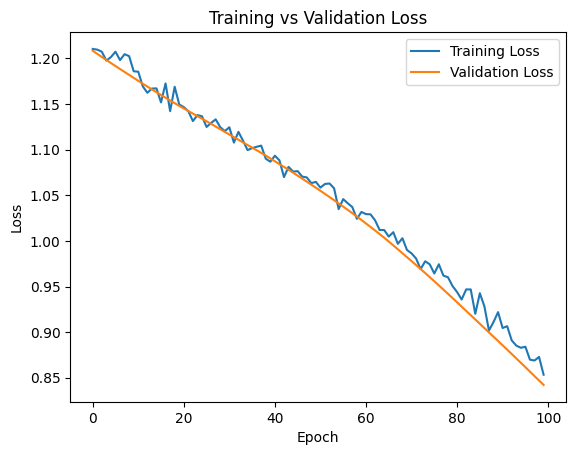

In [4]:

data = load_iris()

X = data.data
y = data.target


X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    random_state=42, stratify=y_temp
)


scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

#  Convert to Tensors
X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
X_val = torch.tensor(X_val, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test, dtype=torch.float32).to(device)

y_train = torch.tensor(y_train, dtype=torch.long).to(device)
y_val = torch.tensor(y_val, dtype=torch.long).to(device)
y_test = torch.tensor(y_test, dtype=torch.long).to(device)

# Build MLP
class IrisMLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(8, 3)
        )

    def forward(self, x):
        return self.network(x)


model = IrisMLP().to(device)

# Loss and Optimizer
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

# Training
epochs = 100

train_losses = []
val_losses = []

for epoch in range(epochs):

    model.train()

    optimizer.zero_grad()

    outputs = model(X_train)

    loss = criterion(outputs, y_train)

    loss.backward()

    optimizer.step()

    train_losses.append(loss.item())

    # Validation
    model.eval()

    with torch.no_grad():
        val_outputs = model(X_val)
        val_loss = criterion(val_outputs, y_val)

    val_losses.append(val_loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {loss.item():.4f} "
            f"Validation Loss: {val_loss.item():.4f}"
        )

model.eval()

with torch.no_grad():
    test_outputs = model(X_test)
    test_predictions = torch.argmax(test_outputs, dim=1)

y_true = y_test.cpu().numpy()
y_pred = test_predictions.cpu().numpy()

print("\nAccuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    target_names=data.target_names
))

cm = confusion_matrix(y_true, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Purples",
            xticklabels=data.target_names,
            yticklabels=data.target_names)

plt.title("Iris Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Loss Graph
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()



# =================================================
# TITANIC CLASSIFICATION USING PYTORCH
# =================================================

Epoch [10/100] Train Loss: 0.6712 Validation Loss: 0.6783
Epoch [20/100] Train Loss: 0.6656 Validation Loss: 0.6695
Epoch [30/100] Train Loss: 0.6570 Validation Loss: 0.6620
Epoch [40/100] Train Loss: 0.6486 Validation Loss: 0.6543
Epoch [50/100] Train Loss: 0.6466 Validation Loss: 0.6458
Epoch [60/100] Train Loss: 0.6317 Validation Loss: 0.6363
Epoch [70/100] Train Loss: 0.6214 Validation Loss: 0.6257
Epoch [80/100] Train Loss: 0.6118 Validation Loss: 0.6128
Epoch [90/100] Train Loss: 0.5967 Validation Loss: 0.5982
Epoch [100/100] Train Loss: 0.5901 Validation Loss: 0.5817

Accuracy: 0.746268656716418

Classification Report:
              precision    recall  f1-score   support

         0.0       0.76      0.86      0.81        83
         1.0       0.71      0.57      0.63        51

    accuracy                           0.75       134
   macro avg       0.74      0.71      0.72       134
weighted avg       0.74      0.75      0.74       134



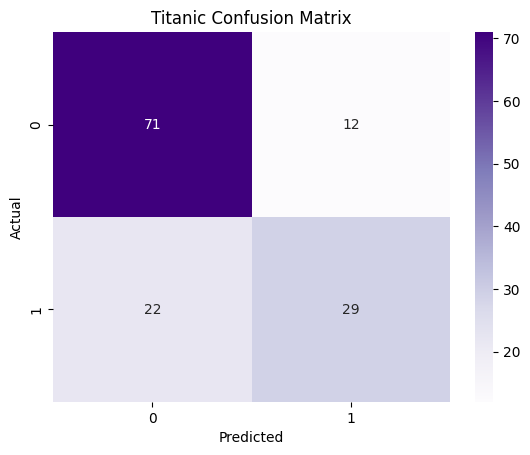

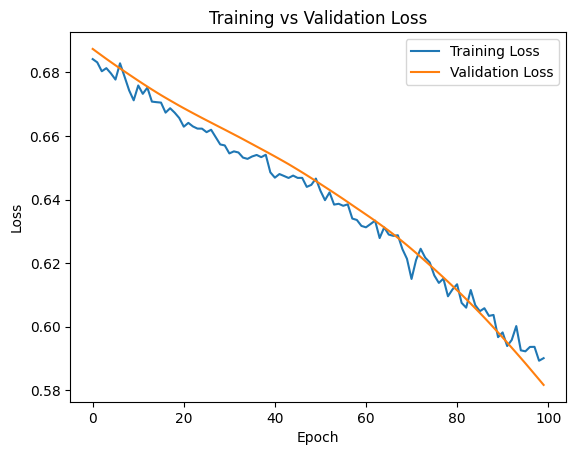

In [6]:



df = sns.load_dataset("titanic")

features = [
    "pclass", "sex", "age", "sibsp",
    "parch", "fare", "embarked"
]

df = df[features + ["survived"]].copy()

#  Split before preprocessing
train_df, temp_df = train_test_split(
    df, test_size=0.30,
    random_state=42,
    stratify=df["survived"]
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.50,
    random_state=42,
    stratify=temp_df["survived"]
)

#  Handle Missing Values Using Training Data
age_median = train_df["age"].median()
fare_median = train_df["fare"].median()
embarked_mode = train_df["embarked"].mode()[0]

def preprocess(data):

    data = data.copy()

    data["age"] = data["age"].fillna(age_median)
    data["fare"] = data["fare"].fillna(fare_median)
    data["embarked"] = data["embarked"].fillna(embarked_mode)

    data["sex"] = data["sex"].map({
        "male": 0,
        "female": 1
    })

    data = pd.get_dummies(
        data,
        columns=["embarked"],
        dtype=int
    )

    expected_columns = [
        "pclass", "sex", "age", "sibsp",
        "parch", "fare",
        "embarked_C", "embarked_Q", "embarked_S"
    ]

    data = data.reindex(
        columns=expected_columns,
        fill_value=0
    )

    return data


X_train = preprocess(train_df)
X_val = preprocess(val_df)
X_test = preprocess(test_df)

y_train = train_df["survived"].values
y_val = val_df["survived"].values
y_test = test_df["survived"].values

# Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

#  Convert to Tensors
X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
X_val = torch.tensor(X_val, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test, dtype=torch.float32).to(device)

y_train = torch.tensor(y_train, dtype=torch.float32).view(-1, 1).to(device)
y_val = torch.tensor(y_val, dtype=torch.float32).view(-1, 1).to(device)
y_test = torch.tensor(y_test, dtype=torch.float32).view(-1, 1).to(device)

#  Build MLP
class TitanicMLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(9, 16),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(8, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)


model = TitanicMLP().to(device)

# Loss and Optimizer
criterion = nn.BCELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)


epochs = 100

train_losses = []
val_losses = []

for epoch in range(epochs):

    model.train()

    optimizer.zero_grad()

    outputs = model(X_train)

    loss = criterion(outputs, y_train)

    loss.backward()

    optimizer.step()

    train_losses.append(loss.item())

    # Validation
    model.eval()

    with torch.no_grad():
        val_outputs = model(X_val)
        val_loss = criterion(val_outputs, y_val)

    val_losses.append(val_loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {loss.item():.4f} "
            f"Validation Loss: {val_loss.item():.4f}"
        )


model.eval()

with torch.no_grad():
    test_probabilities = model(X_test)
    test_predictions = (test_probabilities >= 0.5).int()

y_true = y_test.cpu().numpy()
y_pred = test_predictions.cpu().numpy()

print("\nAccuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred))


cm = confusion_matrix(y_true, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Purples")

plt.title("Titanic Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#  Loss Graph
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


#MLP loss and accuracy visualization

In [7]:

!pip install -q torch scikit-learn pandas matplotlib seaborn


Using device: cpu

BREAST CANCER CLASSIFICATION
Breast Cancer | Epoch 10/100 | Train Loss: 0.6617 | Val Loss: 0.6575 | Train Accuracy: 81.16% | Val Accuracy: 82.35%
Breast Cancer | Epoch 20/100 | Train Loss: 0.6292 | Val Loss: 0.6267 | Train Accuracy: 87.69% | Val Accuracy: 87.06%
Breast Cancer | Epoch 30/100 | Train Loss: 0.5873 | Val Loss: 0.5834 | Train Accuracy: 91.71% | Val Accuracy: 92.94%
Breast Cancer | Epoch 40/100 | Train Loss: 0.5351 | Val Loss: 0.5316 | Train Accuracy: 91.96% | Val Accuracy: 95.29%
Breast Cancer | Epoch 50/100 | Train Loss: 0.4867 | Val Loss: 0.4756 | Train Accuracy: 93.97% | Val Accuracy: 96.47%
Breast Cancer | Epoch 60/100 | Train Loss: 0.4206 | Val Loss: 0.4190 | Train Accuracy: 94.22% | Val Accuracy: 96.47%
Breast Cancer | Epoch 70/100 | Train Loss: 0.3729 | Val Loss: 0.3658 | Train Accuracy: 94.47% | Val Accuracy: 96.47%
Breast Cancer | Epoch 80/100 | Train Loss: 0.3236 | Val Loss: 0.3186 | Train Accuracy: 95.23% | Val Accuracy: 96.47%
Breast Cancer | 

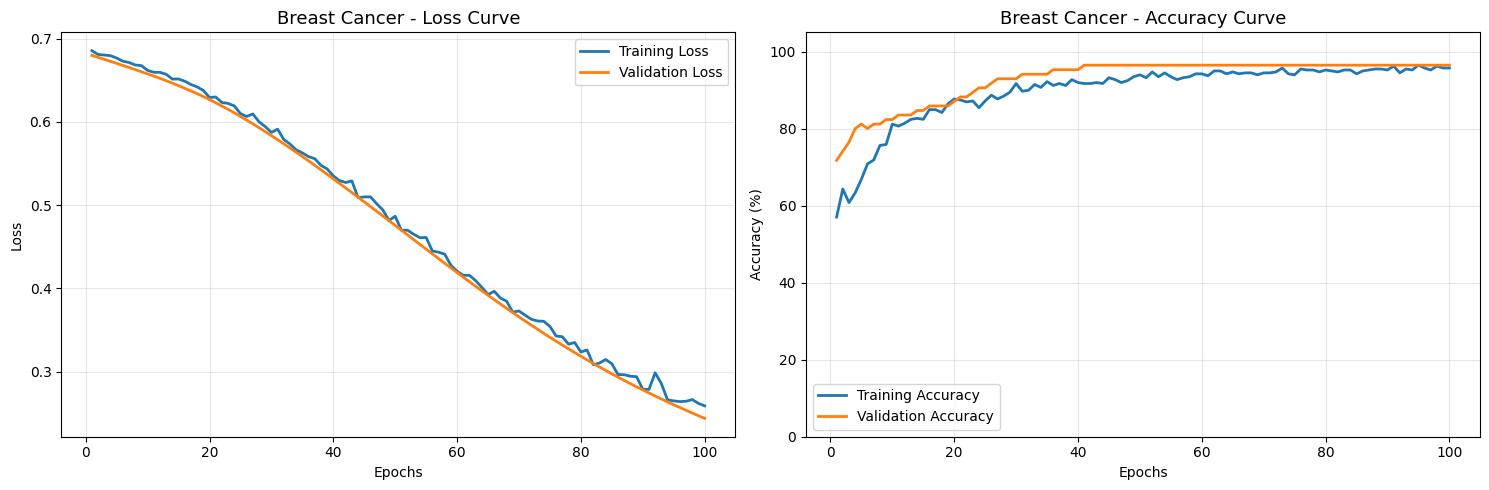


IRIS CLASSIFICATION
Iris | Epoch 10/100 | Train Loss: 1.1859 | Val Loss: 1.1787 | Train Accuracy: 24.76% | Val Accuracy: 13.64%
Iris | Epoch 20/100 | Train Loss: 1.1495 | Val Loss: 1.1480 | Train Accuracy: 25.71% | Val Accuracy: 9.09%
Iris | Epoch 30/100 | Train Loss: 1.1203 | Val Loss: 1.1195 | Train Accuracy: 28.57% | Val Accuracy: 13.64%
Iris | Epoch 40/100 | Train Loss: 1.0868 | Val Loss: 1.0904 | Train Accuracy: 29.52% | Val Accuracy: 18.18%
Iris | Epoch 50/100 | Train Loss: 1.0647 | Val Loss: 1.0583 | Train Accuracy: 27.62% | Val Accuracy: 18.18%
Iris | Epoch 60/100 | Train Loss: 1.0317 | Val Loss: 1.0229 | Train Accuracy: 44.76% | Val Accuracy: 36.36%
Iris | Epoch 70/100 | Train Loss: 0.9901 | Val Loss: 0.9822 | Train Accuracy: 53.33% | Val Accuracy: 50.00%
Iris | Epoch 80/100 | Train Loss: 0.9505 | Val Loss: 0.9374 | Train Accuracy: 65.71% | Val Accuracy: 54.55%
Iris | Epoch 90/100 | Train Loss: 0.9219 | Val Loss: 0.8903 | Train Accuracy: 64.76% | Val Accuracy: 68.18%
Iris | E

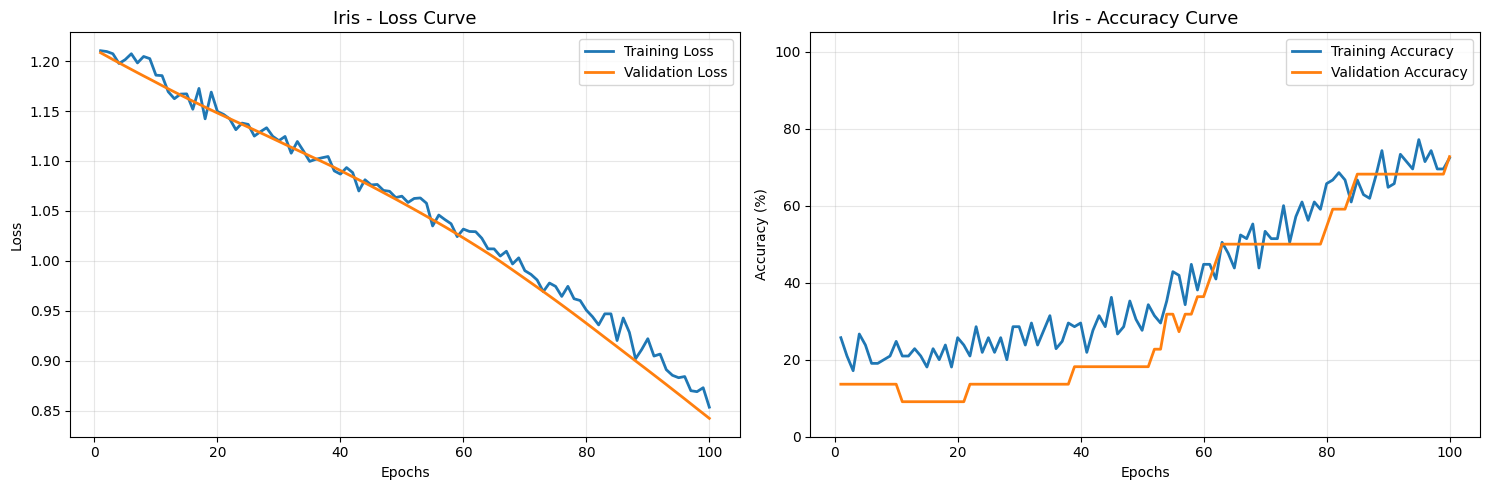


TITANIC CLASSIFICATION
Titanic | Epoch 10/100 | Train Loss: 0.6611 | Val Loss: 0.6619 | Train Accuracy: 61.80% | Val Accuracy: 61.19%
Titanic | Epoch 20/100 | Train Loss: 0.6551 | Val Loss: 0.6521 | Train Accuracy: 61.32% | Val Accuracy: 61.19%
Titanic | Epoch 30/100 | Train Loss: 0.6462 | Val Loss: 0.6406 | Train Accuracy: 63.08% | Val Accuracy: 61.19%
Titanic | Epoch 40/100 | Train Loss: 0.6337 | Val Loss: 0.6266 | Train Accuracy: 65.33% | Val Accuracy: 61.94%
Titanic | Epoch 50/100 | Train Loss: 0.6254 | Val Loss: 0.6108 | Train Accuracy: 68.06% | Val Accuracy: 69.40%
Titanic | Epoch 60/100 | Train Loss: 0.6046 | Val Loss: 0.5936 | Train Accuracy: 73.84% | Val Accuracy: 79.85%
Titanic | Epoch 70/100 | Train Loss: 0.5907 | Val Loss: 0.5747 | Train Accuracy: 74.80% | Val Accuracy: 81.34%
Titanic | Epoch 80/100 | Train Loss: 0.5744 | Val Loss: 0.5546 | Train Accuracy: 76.24% | Val Accuracy: 79.85%
Titanic | Epoch 90/100 | Train Loss: 0.5648 | Val Loss: 0.5345 | Train Accuracy: 77.21% 

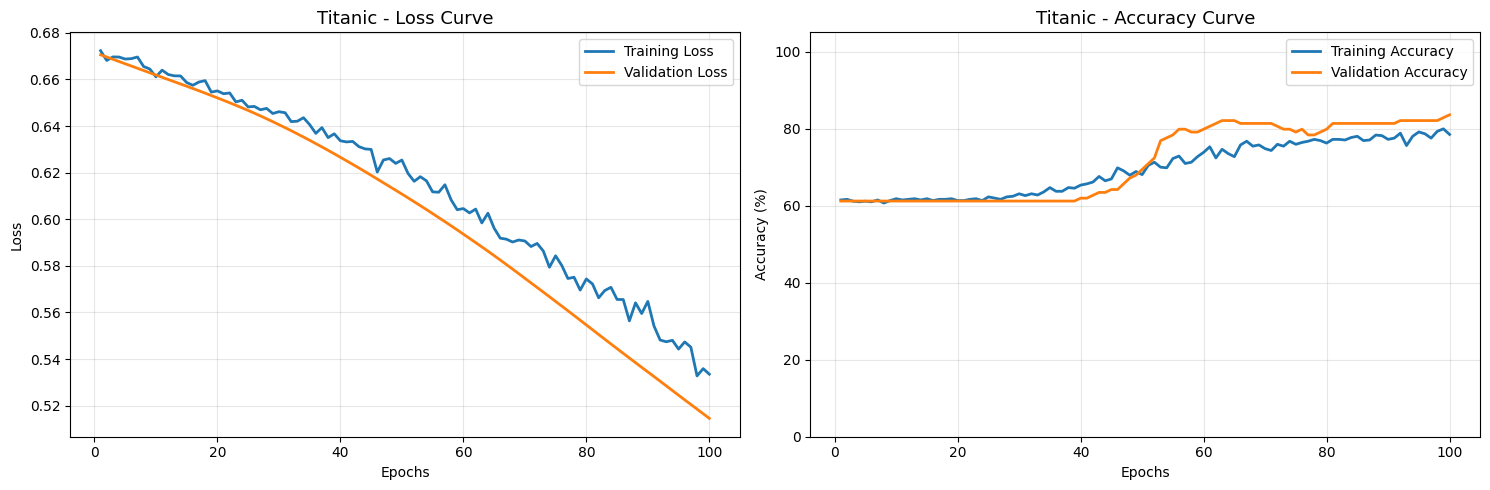


FINAL MODEL PERFORMANCE COMPARISON
      Dataset  Test Accuracy
Breast Cancer      93.023256
         Iris      65.217391
      Titanic      77.611940


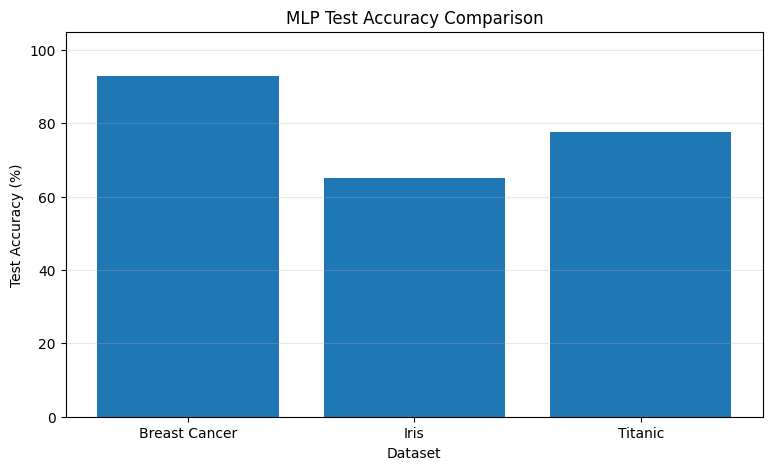

In [8]:

import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


# ============================================================
#  COMMON MLP MODEL
# ============================================================

class MLP(nn.Module):

    def __init__(self, input_size, output_size, binary=True):

        super().__init__()

        layers = [
            nn.Linear(input_size, 16),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(8, output_size)
        ]

        if binary:
            layers.append(nn.Sigmoid())

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


# ============================================================
#  TRAINING AND VISUALIZATION FUNCTION
# ============================================================

def train_and_visualize(
    X_train, X_val, X_test,
    y_train, y_val, y_test,
    dataset_name,
    binary=True,
    class_names=None,
    epochs=100
):

    # Convert data into tensors
    X_train = torch.tensor(
        X_train, dtype=torch.float32
    ).to(device)

    X_val = torch.tensor(
        X_val, dtype=torch.float32
    ).to(device)

    X_test = torch.tensor(
        X_test, dtype=torch.float32
    ).to(device)

    if binary:

        y_train = torch.tensor(
            y_train, dtype=torch.float32
        ).view(-1, 1).to(device)

        y_val = torch.tensor(
            y_val, dtype=torch.float32
        ).view(-1, 1).to(device)

        y_test = torch.tensor(
            y_test, dtype=torch.float32
        ).view(-1, 1).to(device)

        output_size = 1
        criterion = nn.BCELoss()

    else:

        y_train = torch.tensor(
            y_train, dtype=torch.long
        ).to(device)

        y_val = torch.tensor(
            y_val, dtype=torch.long
        ).to(device)

        y_test = torch.tensor(
            y_test, dtype=torch.long
        ).to(device)

        output_size = len(np.unique(y_train.cpu().numpy()))
        criterion = nn.CrossEntropyLoss()

    # Build model
    model = MLP(
        input_size=X_train.shape[1],
        output_size=output_size,
        binary=binary
    ).to(device)

    # Adam + L2 regularization
    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=0.0001
    )

    # Store metrics
    train_losses = []
    val_losses = []

    train_accuracies = []
    val_accuracies = []

    # ========================================================
    # TRAINING LOOP
    # ========================================================

    for epoch in range(epochs):

        model.train()

        optimizer.zero_grad()

        outputs = model(X_train)

        loss = criterion(outputs, y_train)

        loss.backward()

        optimizer.step()

        train_losses.append(loss.item())

        # Training accuracy
        if binary:

            train_preds = (
                outputs >= 0.5
            ).float()

        else:

            train_preds = torch.argmax(
                outputs, dim=1
            )

        train_acc = (
            train_preds == y_train
        ).float().mean().item()

        train_accuracies.append(train_acc * 100)

        # ====================================================
        # VALIDATION
        # ====================================================

        model.eval()

        with torch.no_grad():

            val_outputs = model(X_val)

            val_loss = criterion(
                val_outputs, y_val
            )

            if binary:

                val_preds = (
                    val_outputs >= 0.5
                ).float()

            else:

                val_preds = torch.argmax(
                    val_outputs, dim=1
                )

            val_acc = (
                val_preds == y_val
            ).float().mean().item()

        val_losses.append(val_loss.item())

        val_accuracies.append(val_acc * 100)

        # Display progress
        if (epoch + 1) % 10 == 0:

            print(
                f"{dataset_name} | "
                f"Epoch {epoch+1}/{epochs} | "
                f"Train Loss: {loss.item():.4f} | "
                f"Val Loss: {val_loss.item():.4f} | "
                f"Train Accuracy: {train_acc*100:.2f}% | "
                f"Val Accuracy: {val_acc*100:.2f}%"
            )

    # ========================================================
    # FINAL TEST EVALUATION
    # ========================================================

    model.eval()

    with torch.no_grad():

        test_outputs = model(X_test)

        if binary:

            test_preds = (
                test_outputs >= 0.5
            ).int()

        else:

            test_preds = torch.argmax(
                test_outputs, dim=1
            )

    y_true = y_test.cpu().numpy().flatten()
    y_pred = test_preds.cpu().numpy().flatten()

    test_accuracy = accuracy_score(
        y_true, y_pred
    )

    print("\n" + "=" * 55)
    print(dataset_name, "FINAL TEST RESULTS")
    print("=" * 55)

    print(
        f"Test Accuracy: {test_accuracy * 100:.2f}%"
    )

    print("\nClassification Report:")

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=class_names,
            zero_division=0
        )
    )

    # ========================================================
    # LOSS AND ACCURACY VISUALIZATION
    # ========================================================

    epoch_range = range(1, epochs + 1)

    plt.figure(figsize=(15, 5))

    # Training and Validation Loss
    plt.subplot(1, 2, 1)

    plt.plot(
        epoch_range,
        train_losses,
        label="Training Loss",
        linewidth=2
    )

    plt.plot(
        epoch_range,
        val_losses,
        label="Validation Loss",
        linewidth=2
    )

    plt.title(
        f"{dataset_name} - Loss Curve",
        fontsize=13
    )

    plt.xlabel("Epochs")
    plt.ylabel("Loss")

    plt.legend()
    plt.grid(alpha=0.3)

    # Training and Validation Accuracy
    plt.subplot(1, 2, 2)

    plt.plot(
        epoch_range,
        train_accuracies,
        label="Training Accuracy",
        linewidth=2
    )

    plt.plot(
        epoch_range,
        val_accuracies,
        label="Validation Accuracy",
        linewidth=2
    )

    plt.title(
        f"{dataset_name} - Accuracy Curve",
        fontsize=13
    )

    plt.xlabel("Epochs")
    plt.ylabel("Accuracy (%)")

    plt.ylim(0, 105)

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return {
        "Dataset": dataset_name,
        "Test Accuracy": test_accuracy * 100,
        "Model": model,
        "Train Loss": train_losses,
        "Validation Loss": val_losses,
        "Train Accuracy": train_accuracies,
        "Validation Accuracy": val_accuracies
    }


# ============================================================
# BREAST CANCER DATASET
# BINARY CLASSIFICATION
# ============================================================

print("\nBREAST CANCER CLASSIFICATION")

cancer = load_breast_cancer()

X = cancer.data
y = cancer.target

# Split data: 70% train, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# Train and visualize
cancer_results = train_and_visualize(
    X_train, X_val, X_test,
    y_train, y_val, y_test,
    dataset_name="Breast Cancer",
    binary=True,
    class_names=list(cancer.target_names),
    epochs=100
)


# ============================================================
# IRIS DATASET
# MULTI-CLASS CLASSIFICATION
# ============================================================

print("\nIRIS CLASSIFICATION")

iris = load_iris()

X = iris.data
y = iris.target

# Split data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# Train and visualize
iris_results = train_and_visualize(
    X_train, X_val, X_test,
    y_train, y_val, y_test,
    dataset_name="Iris",
    binary=False,
    class_names=list(iris.target_names),
    epochs=100
)


# ============================================================
# TITANIC DATASET
# BINARY CLASSIFICATION
# ============================================================

print("\nTITANIC CLASSIFICATION")

# Load Titanic dataset
df = sns.load_dataset("titanic")

features = [
    "pclass", "sex", "age",
    "sibsp", "parch", "fare", "embarked"
]

df = df[features + ["survived"]].copy()

# Split before preprocessing
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["survived"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["survived"]
)

# Fit missing-value replacements on training data only
age_median = train_df["age"].median()
fare_median = train_df["fare"].median()
embarked_mode = train_df["embarked"].mode()[0]

def preprocess_titanic(data):

    data = data.copy()

    data["age"] = data["age"].fillna(age_median)
    data["fare"] = data["fare"].fillna(fare_median)
    data["embarked"] = data["embarked"].fillna(embarked_mode)

    data["sex"] = data["sex"].map({
        "male": 0,
        "female": 1
    })

    data = pd.get_dummies(
        data,
        columns=["embarked"],
        dtype=int
    )

    expected_columns = [
        "pclass", "sex", "age",
        "sibsp", "parch", "fare",
        "embarked_C", "embarked_Q", "embarked_S"
    ]

    return data.reindex(
        columns=expected_columns,
        fill_value=0
    )

# Preprocess
X_train = preprocess_titanic(train_df)
X_val = preprocess_titanic(val_df)
X_test = preprocess_titanic(test_df)

y_train = train_df["survived"].values
y_val = val_df["survived"].values
y_test = test_df["survived"].values

# Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# Train and visualize
titanic_results = train_and_visualize(
    X_train, X_val, X_test,
    y_train, y_val, y_test,
    dataset_name="Titanic",
    binary=True,
    class_names=["Not Survived", "Survived"],
    epochs=100
)


# ============================================================
#  FINAL COMPARISON OF THREE DATASETS
# ============================================================

results = pd.DataFrame([
    {
        "Dataset": cancer_results["Dataset"],
        "Test Accuracy": cancer_results["Test Accuracy"]
    },
    {
        "Dataset": iris_results["Dataset"],
        "Test Accuracy": iris_results["Test Accuracy"]
    },
    {
        "Dataset": titanic_results["Dataset"],
        "Test Accuracy": titanic_results["Test Accuracy"]
    }
])

print("\nFINAL MODEL PERFORMANCE COMPARISON")
print(results.to_string(index=False))

# Accuracy comparison graph
plt.figure(figsize=(9, 5))

plt.bar(
    results["Dataset"],
    results["Test Accuracy"]
)

plt.title("MLP Test Accuracy Comparison")
plt.xlabel("Dataset")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 105)

plt.grid(axis="y", alpha=0.3)
plt.show()

